# Город для 40 кофейных автоматов

Совет принимает риск годового убытка не выше 2,5 %. Из допустимых городов выбираем лидера по средней чистой прибыли. Расчёты ниже в тысячах рублей.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
RANDOM_STATE=42
MODEL_SEED=0
DATA=Path("data")
s=pd.read_csv(DATA/"sites.csv")

## 1. Цель и данные

Есть три города по 1 500 обследованных точек. На следующем этапе разведка отберёт 300 мест в выбранном городе, из них под модельный прогноз берём лучшие 40. Один автомат обходится в 140 тыс. ₽ за год.

In [2]:
v=s.assign(pays=s.profit_k>140)
overview=v.groupby("city").agg(sites=("site_id","size"),mean_profit=("profit_k","mean"),pays_off=("pays","mean"))
overview["mean_profit"]=overview.mean_profit.round(1)
overview["pays_off"]=overview.pays_off.round(3)
best_avg_city=overview.mean_profit.idxmax()
overview

,sites,mean_profit,pays_off
city,,,
Екатеринбург,1500,70.9,0.291
Казань,1500,66.9,0.206
Пермь,1500,65.2,0.159


Средняя прибыль места до стоимости автомата выше в Екатеринбурге (70,9 тыс. ₽). По одному среднему нельзя судить о будущих 40 выбранных местах.

## 2. Качество прогноза и выбор мест

In [3]:
def prep(part):
    x=pd.get_dummies(part[["place","traffic","offices","competitors","rent_k","hours24"]],dtype=int)
    x["traffic"]=np.log(x.traffic)
    return x
X_perm=prep(s[s.city=="Пермь"])
rows={}
fits={}
for city,v in s.groupby("city"):
    a,b,u,f=train_test_split(prep(v),v.profit_k,test_size=.25,random_state=RANDOM_STATE)
    m=LinearRegression().fit(a,u)
    p=pd.Series(m.predict(b),index=b.index)
    fits[city]=(p,f)
    rows[city]=[round(m.score(b,f),3),round(((f-p)**2).mean()**.5,1)]
quality=pd.DataFrame.from_dict(rows,orient="index",columns=["r2","rmse"])
most_predictable=quality.r2.idxmax()
quality

,r2,rmse
Екатеринбург,0.230,112.8
Казань,0.491,61.8
Пермь,0.730,37.8


In [4]:
rows={}
for city,(pred,fact) in fits.items():
    idx=pred.nlargest(40).index
    rows[city]=[round(fact[idx].sum()-5600),round(40*fact.mean()-5600)]
top=pd.DataFrame.from_dict(rows,orient="index",columns=["model","random"])
print(top)
rows={}
for city,(p,f) in fits.items():
    i=p.nlargest(40).index
    a,b=p[i].sum()-5600,f[i].sum()-5600
    rows[city]=[round(a),round(b),round(b-a)]
promise=pd.DataFrame.from_dict(rows,orient="index",columns=["promised","actual","gap"])
overpromised=promise.index[promise.gap<0].tolist()
promise

              model  random
Екатеринбург   1475   -2779
Казань          619   -3083
Пермь          1479   -2883


,promised,actual,gap
Екатеринбург,1176,1475,299
Казань,997,619,-378
Пермь,1193,1479,286


RMSE в Перми — 37,8 тыс. ₽, в Екатеринбурге — 112,8 тыс. ₽. Лучшие 40 по прогнозу в Перми дали 1 479 тыс. ₽ после затрат, случайные 40 в среднем дали бы −2 883 тыс. ₽. В таблице разница «факт минус обещание» меняет знак между городами.

## 3. Бутстрэп и ограничения обследования

In [5]:
def boot_city(pred,fact):
    rng=np.random.default_rng(MODEL_SEED)
    p,f=np.asarray(pred),np.asarray(fact)
    out=[]
    for _ in range(1000):
        i=rng.integers(0,len(f),300)
        top=i[np.argsort(-p[i])[:40]]
        out.append(f[top].sum()-5600)
    return np.array(out)
rows={}
for city,(pred,fact) in fits.items():
    v=boot_city(pred,fact)
    rows[city]=[round(v.mean()),round(np.percentile(v,2.5)),round(np.percentile(v,97.5)),round((v<0).mean(),3)]
risk=pd.DataFrame.from_dict(rows,orient="index",columns=["mean","low","high","p_loss"])
passed=risk.index[risk.p_loss<=.025].tolist()
choice=risk.loc[passed,"mean"].idxmax()
cost_of_safety=risk["mean"].max()-risk.loc[choice,"mean"]
print(risk,choice,cost_of_safety)

              mean  low  high  p_loss
Екатеринбург  1426 -239  2961   0.046
Казань         498 -286  1372   0.121
Пермь         1121  393  1846   0.001 Пермь 305


Различных адресов в сорока строках первого повтора 30


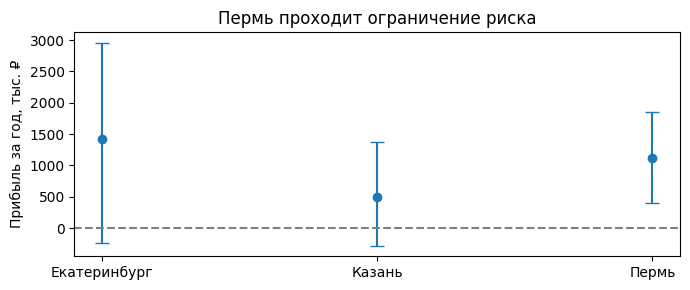

In [6]:
pred,fact=fits["Пермь"]
rng=np.random.default_rng(MODEL_SEED)
idx=rng.integers(0,len(pred),300)
selected=idx[np.argsort(-pred.to_numpy()[idx])[:40]]
print("Различных адресов в сорока строках первого повтора",len(set(selected)))
fig,ax=plt.subplots(figsize=(7,3))
ax.errorbar(risk.index,risk["mean"],yerr=[risk["mean"]-risk.low,risk.high-risk["mean"]],fmt="o",capsize=5)
ax.axhline(0,color="gray",linestyle="--")
ax.set(ylabel="Прибыль за год, тыс. ₽",title="Пермь проходит ограничение риска")
fig.tight_layout()
plt.show()

В 1 000 повторах нижняя и верхняя границы для Перми составили 393 и 1 846 тыс. ₽, убыток возник в одном повторе. Средняя у Екатеринбурга выше на 305 тыс. ₽, но убыток случался в 4,6 % прогонов. Повторы с возвращением представляют новые локации с характеристиками похожих известных мест; в исходном бутстрэпе один исторический адрес может встречаться дважды.

## 4. Профиль места и проверка лесом

In [7]:
idx=pred.nlargest(40).index
a,b=s.loc[idx],s.loc[fact.index]
bc_share=round((a.place=="бизнес-центр").mean(),3)
pays_top,pays_all=round((a.profit_k>140).mean(),3),round((b.profit_k>140).mean(),3)
traffic_top,traffic_all=a.traffic.median(),b.traffic.median()
comp_top,comp_all=a.competitors.median(),b.competitors.median()
rent_top,rent_all=a.rent_k.median(),b.rent_k.median()
print(bc_share,pays_top,pays_all,traffic_top,traffic_all,comp_top,comp_all,rent_top,rent_all)

0.725 0.775 0.149 1538.0 736.0 0.0 1.0 50.0 70.0


In [8]:
rows={}
for city in ["Пермь","Екатеринбург"]:
    v=s[s.city==city]
    a,b,u,f=train_test_split(prep(v),v.profit_k,test_size=.25,random_state=RANDOM_STATE)
    m=RandomForestRegressor(n_estimators=100,min_samples_leaf=5,random_state=MODEL_SEED).fit(a,u)
    p=pd.Series(m.predict(b),index=b.index)
    z=boot_city(p,f)
    rows[city]=[round(m.score(b,f),3),round(z.mean()),round((z<0).mean(),3)]
rf_risk=pd.DataFrame.from_dict(rows,orient="index",columns=["r2","mean","p_loss"])
v=rf_risk[rf_risk.p_loss<=.025]
same_choice=len(v)>0 and v["mean"].idxmax()=="Пермь" 
print(rf_risk,same_choice)

                 r2  mean  p_loss
Пермь         0.647   881   0.006
Екатеринбург  0.173   814   0.169 True


Среди сорока лучших тестовых мест Перми 72,5 % — бизнес-центры. Медиана трафика 1 538 против 736 по всем тестовым местам, конкурентов 0 против 1. На лесу выбор города сохранился.

## 5. Выводы и рекомендации

Выбрать Пермь. При установленной схеме повторения обследования ожидаемая годовая прибыль за вычетом пяти миллионов шестисот тысяч рублей затрат — 1 121 тыс. ₽, риск убытка 0,1 %. Для размещения потребуются 40 разных адресов из будущей разведки; тестовые примеры служат оценке стратегии. Если расходы или доступность мест изменятся, правило нужно пересчитать.